# Instance segmentation — quickstart

**Instance segmentation** outlines every object *individually*: for each one you get a class, a score, a box and a **pixel mask**. Two touching circles give two separate masks — that's what separates it from semantic segmentation, which only says "circle pixels".

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 10 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/instance_segmentation/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("instance_segmentation", cfg)
print("task:", "instance_segmentation", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: instance_segmentation | data: data/demo/instance_segmentation | outputs: outputs/instance_segmentation_quick


## 1 · The data
A few examples, with their labels:

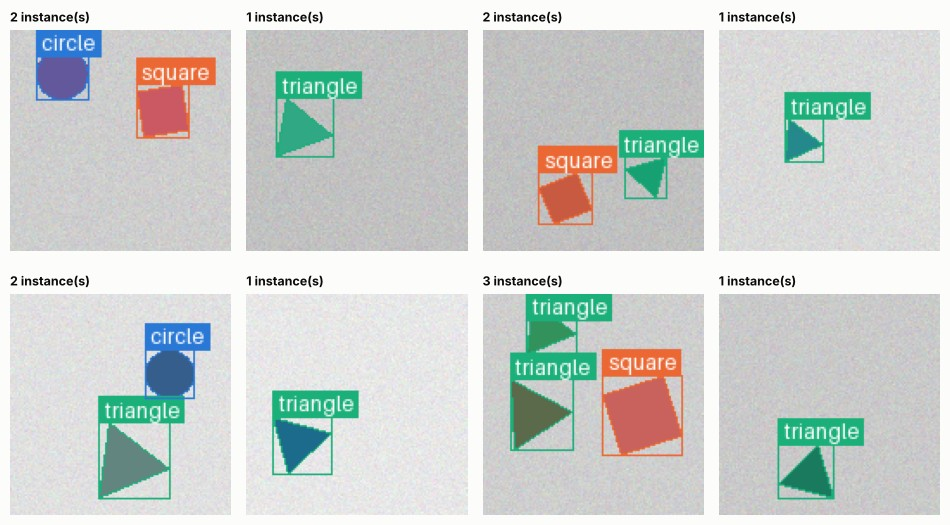

In [3]:
import numpy as np
from PIL import Image
from cvkit.coco import load_coco, polygons_to_mask
from cvkit.viz import draw_boxes, image_grid, overlay_masks

coco = load_coco(cfg["data"]["root"], cfg["data"].get("annotations", "annotations.json"), cfg["data"].get("images_dir", "images"))
classes, items = coco["classes"], coco["images"]

def show(im):
    anns = im["annotations"]
    masks = np.stack([polygons_to_mask(a["segmentation"], im["height"], im["width"]) for a in anns])
    shaded = overlay_masks(Image.open(im["path"]), masks, [a["label"] for a in anns])
    return draw_boxes(shaded, [a["bbox"] for a in anns], [a["label"] for a in anns], classes=classes, width=1)
_ = image_grid([show(im) for im in items[:8]], [f"{len(im['annotations'])} instance(s)" for im in items[:8]], cols=4, cell=2.4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit instance_segmentation train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.instance_segmentation.train import train

result = train(cfg)

arch: maskrcnn_resnet18_fpn | classes (3): ['circle', 'square', 'triangle']


device: cpu | parameters: 30,917,479 total, 30,917,479 trainable (100.0%)


epoch   1/15 | train_loss 7.3513 | val mask_map=0.032 mask_map50=0.071 box_map=0.013 box_map50=0.044 | 34.8s  <- best


epoch   2/15 | train_loss 1.2545 | val mask_map=0.309 mask_map50=0.439 box_map=0.163 box_map50=0.388 | 35.0s  <- best


epoch   3/15 | train_loss 0.9984 | val mask_map=0.318 mask_map50=0.500 box_map=0.198 box_map50=0.463 | 34.9s  <- best


...

epoch  11/15 | train_loss 0.3114 | val mask_map=0.870 mask_map50=0.998 box_map=0.856 box_map50=0.998 | 36.6s  <- best


epoch  12/15 | train_loss 0.2711 | val mask_map=0.854 mask_map50=0.998 box_map=0.897 box_map50=0.998 | 37.1s


epoch  13/15 | train_loss 0.2438 | val mask_map=0.864 mask_map50=0.997 box_map=0.907 box_map50=0.997 | 36.4s


epoch  14/15 | train_loss 0.2180 | val mask_map=0.867 mask_map50=0.997 box_map=0.918 box_map50=0.997 | 36.3s


epoch  15/15 | train_loss 0.2228 | val mask_map=0.875 mask_map50=0.998 box_map=0.921 box_map50=0.998 | 34.9s  <- best
best val mask_map = 0.8755 (epoch 15) -> outputs/instance_segmentation_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.instance_segmentation.evaluate import evaluate

metrics = evaluate(cfg)

mask mAP@[.5:.95] 0.865 | mask mAP@.5 1.000 | mask mAP@.75 1.000
box  mAP@[.5:.95] 0.920 | box  mAP@.5 1.000  (36 test images)
at score >= 0.5: precision 0.952 | recall 1.000 (TP 79, FP 4, FN 0)
reports -> outputs/instance_segmentation_quick/reports


ap_per_class.png


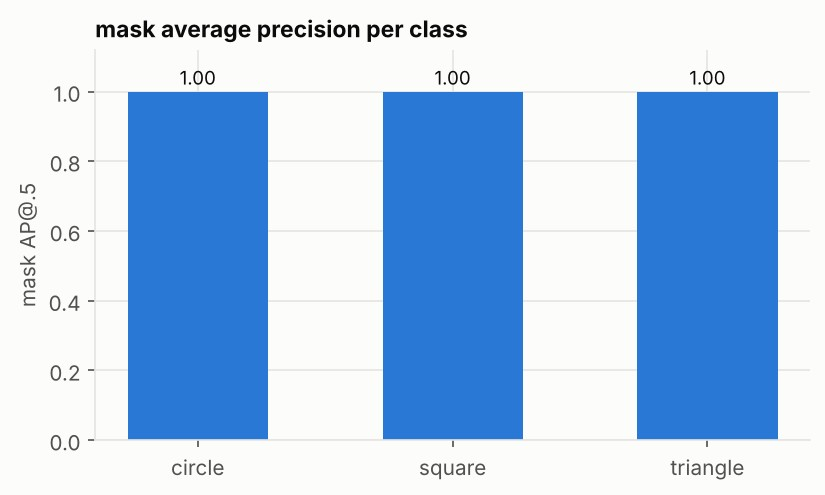

predictions.png


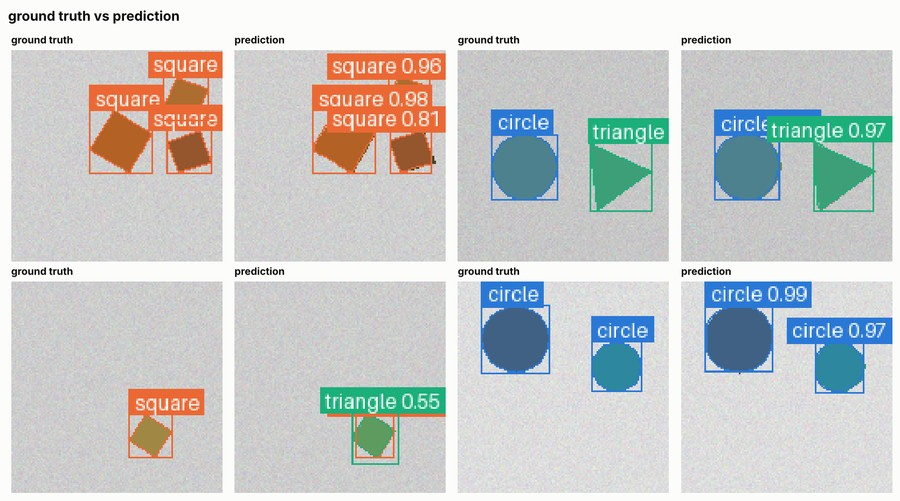

worst_images.png


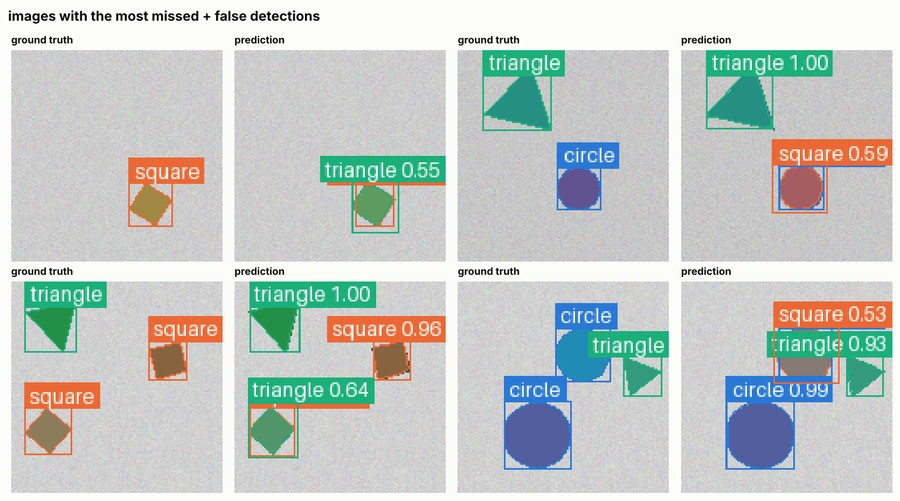

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['ap_per_class.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

**Reading it:** `predictions.png` shows true masks next to predicted masks (one colour per class). The headline number is **mask mAP**: overlap is measured between masks, so it checks the *outline*, not just the bounding rectangle. It is always lower than box mAP.

## 4 · Predict
`Predictor.predict` returns one dict per object, including a boolean `mask` the size of the image:

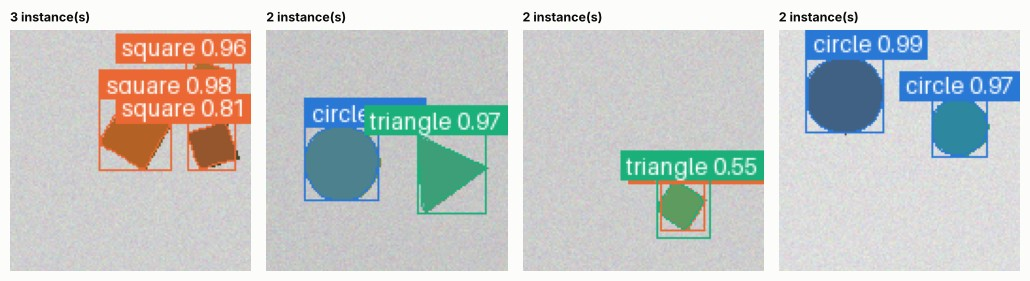

In [7]:
from cvkit.viz import image_grid
from tasks.instance_segmentation.predict import Predictor
from tasks.instance_segmentation.data import test_image_paths

predictor = Predictor.from_config(cfg)
paths = test_image_paths(cfg, 4)
objs = [predictor.predict(p) for p in paths]
_ = image_grid([predictor.visualize(p, o) for p, o in zip(paths, objs)], [f"{len(o)} instance(s)" for o in objs], cols=4, cell=2.6)

## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)